# Import Libraries

In [2]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
import random
import warnings
from tensorflow.keras.datasets import mnist
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.stattools import grangercausalitytests, adfuller, kpss

# Part 1: K-Nearest Neighbors

## Task 1

### Load Dataset

In [20]:
df = pd.read_csv('airline_passenger_satisfaction.csv')
df

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,129876,Male,28,Returning,Personal,Economy Plus,447,2,3.0,4,...,5,1,4,4,4,5,4,4,4,Neutral or Dissatisfied
129876,129877,Male,41,Returning,Personal,Economy Plus,308,0,0.0,5,...,5,2,5,2,2,4,3,2,5,Neutral or Dissatisfied
129877,129878,Male,42,Returning,Personal,Economy Plus,337,6,14.0,5,...,3,3,4,3,3,4,2,3,5,Neutral or Dissatisfied
129878,129879,Male,50,Returning,Personal,Economy Plus,337,31,22.0,4,...,4,4,5,3,3,4,5,3,5,Satisfied


### Histograms

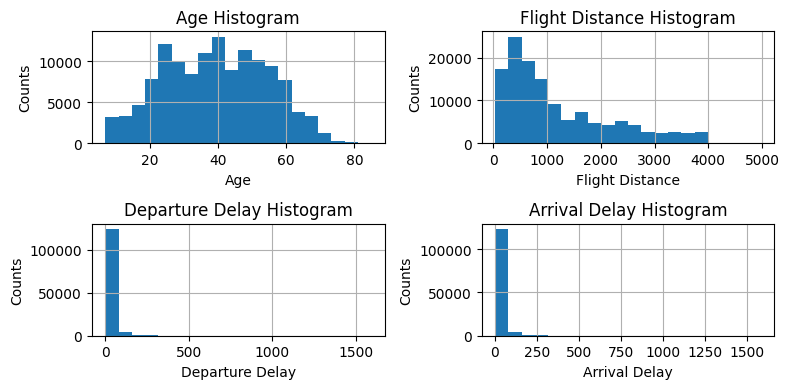

In [21]:
columns = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']
figure, axes = plt.subplots(2, 2, figsize=(8,4))

axes = axes.flatten()
for idx, col in enumerate(columns):
    df[col].hist(bins=20, ax=axes[idx])
    axes[idx].set_title(f'{col} Histogram')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Counts')

plt.tight_layout()
plt.show()

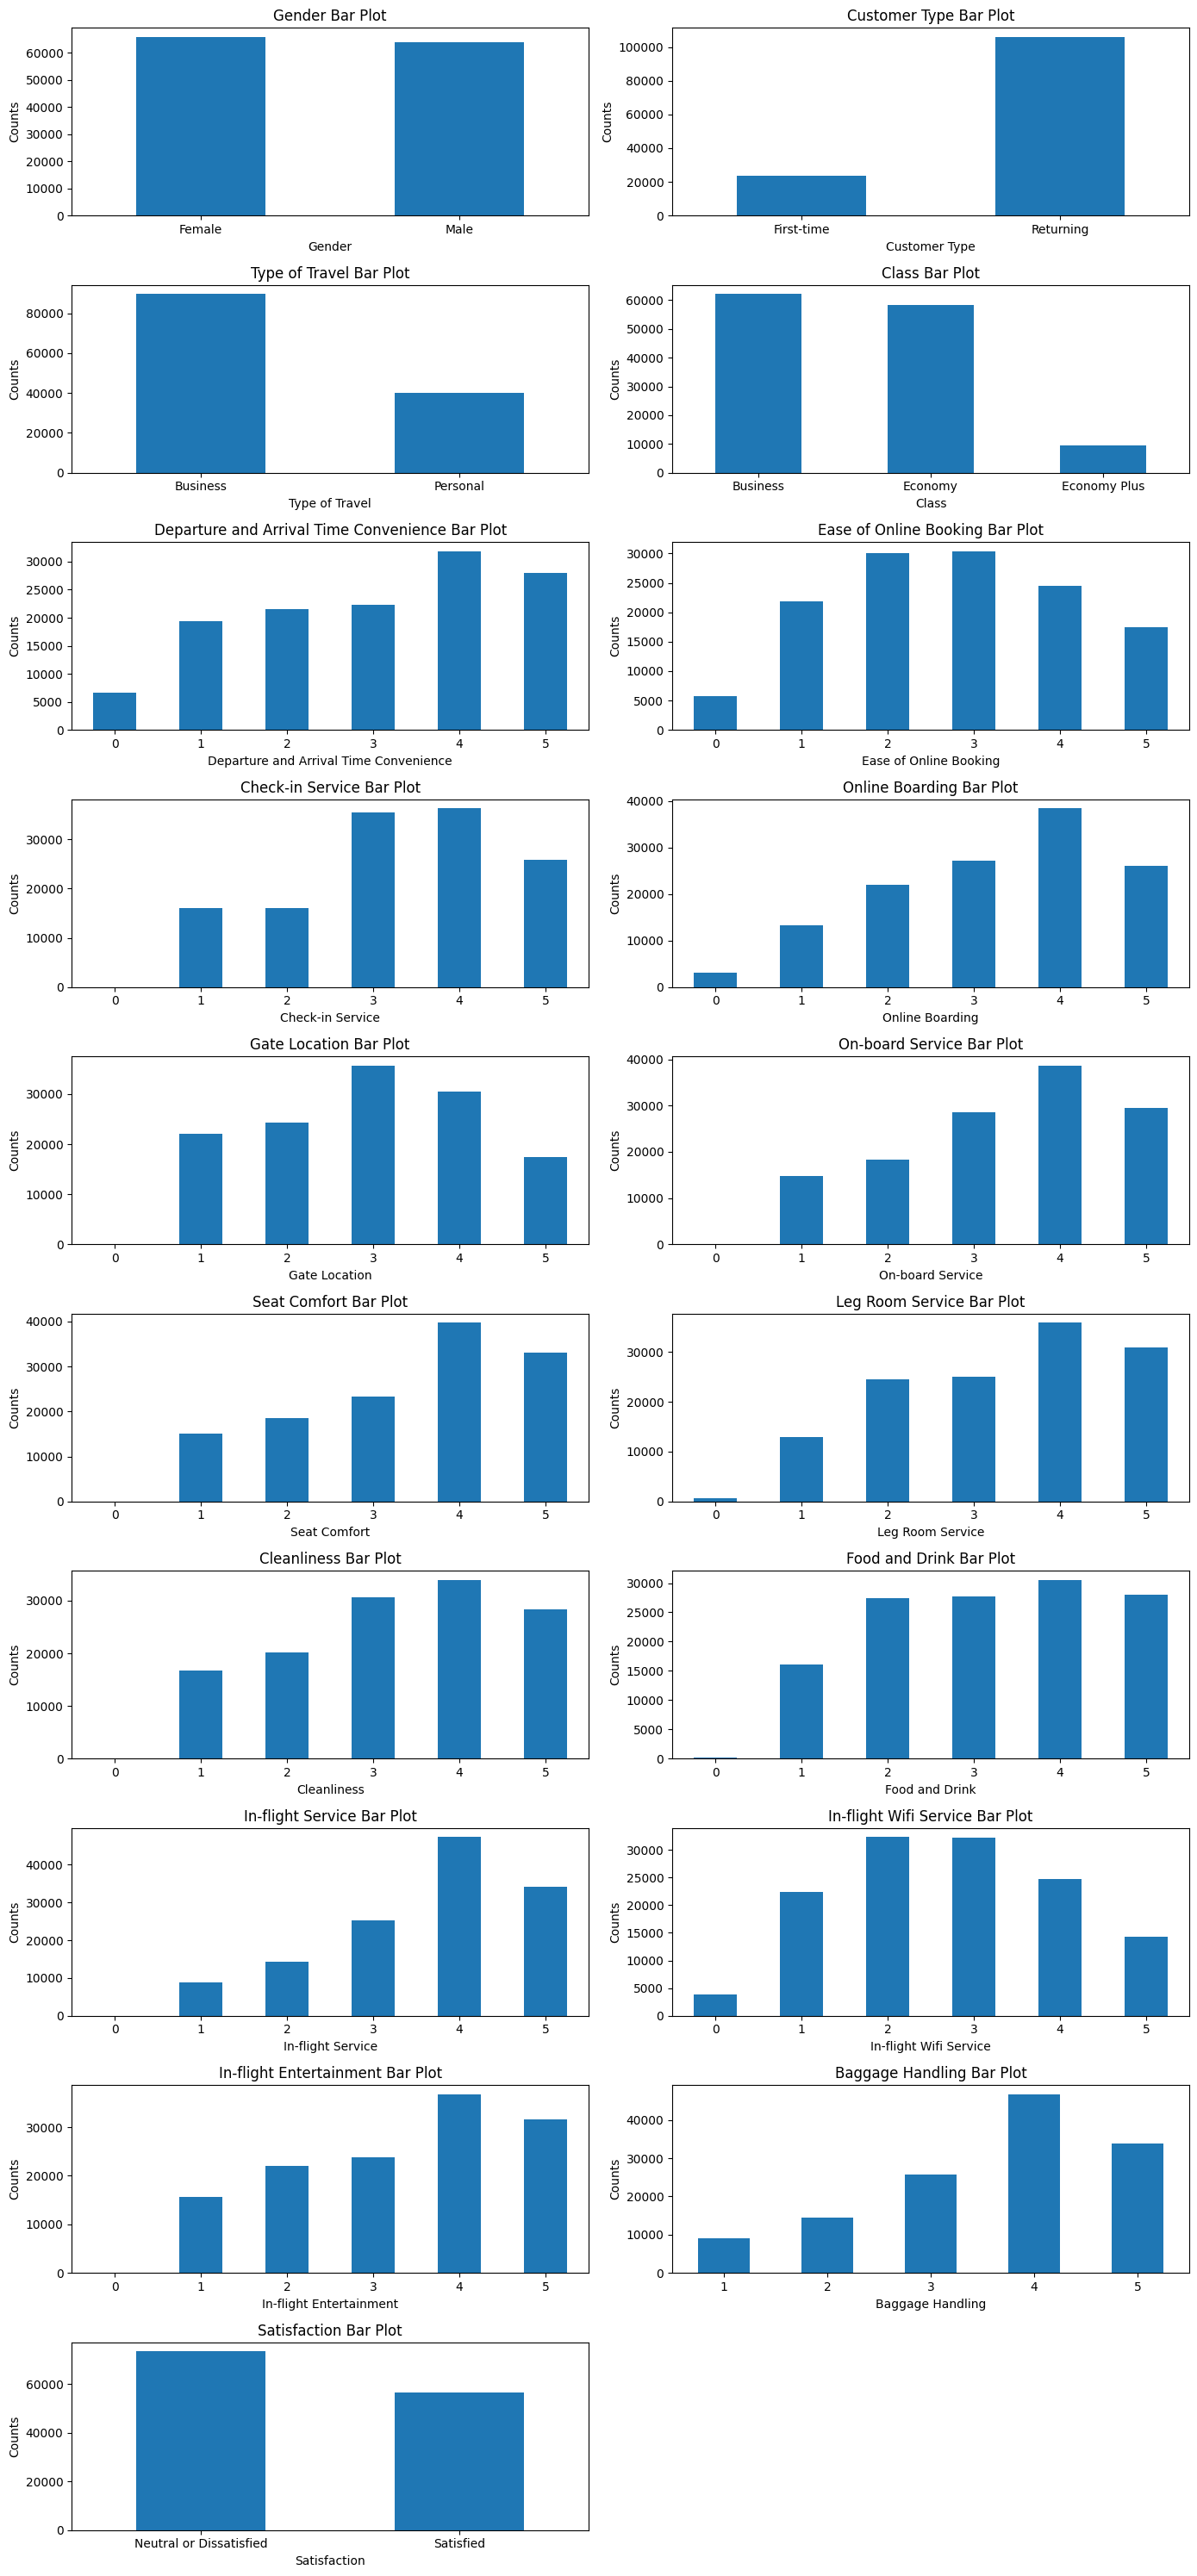

In [22]:
columns = ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service' , 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Satisfaction']
figure, axes = plt.subplots(10, 2, figsize=(14, 30))
axes = axes.flatten()

for idx, col in enumerate(columns):
    df[col].value_counts().sort_index().plot.bar(ax=axes[idx])
    axes[idx].tick_params(axis='x', rotation=0)
    axes[idx].set_title(f'{col} Bar Plot')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Counts')

axes[-1].set_visible(False)

plt.tight_layout()
plt.show()

### Class Imbalance

In [23]:
df['Satisfaction'].value_counts()
df['Satisfaction'].value_counts(normalize=True)

,proportion
Satisfaction,
Neutral or Dissatisfied,0.565537
Satisfied,0.434463


The class `Neutral or Dissatisfied` prevails `Satisfied` (~56% vs 43%) but the imbalance is mild.

## Task 2

## Encoding

In [24]:
df['Gender'] = df['Gender'].map({'Female': 0, 'Male': 1})
df['Customer Type'] = df['Customer Type'].map({'First-time': 0, 'Returning': 1})
df['Type of Travel'] = df['Type of Travel'].map({'Personal': 0, 'Business': 1})
df['Satisfaction'] = df['Satisfaction'].map({'Neutral or Dissatisfied': 0, 'Satisfied': 1})

df['Class'] = df['Class'].map({'Economy': 0, 'Economy Plus': 1, 'Business': 2})

I used Ordinal Encoding for the `Class` column because Ordinal tells the distance metric that Economy is closer to Economy Plus than to Business. It can be a useful assumption for the KNN model.

## Task 3

### Convert DataFrame to Numpy arrays

In [40]:
df = df.dropna().reset_index(drop=True) # For KNN to work, NaN values should get removed
input_df = df.drop(columns=['Satisfaction', 'ID'])
targets_df = df['Satisfaction']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((129487, 22), (129487,))

### Train and Test split

In [41]:
seed = 0

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((90640, 22), (90640,), (38847, 22), (38847,))

## Task 4

### Normalization

In [42]:
columns = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']
idx = [input_df.columns.get_loc(c) for c in columns]

scaler = StandardScaler()
x_train[:, idx] = scaler.fit_transform(x_train[:, idx])
x_test[:, idx] = scaler.transform(x_test[:, idx])

I used `StandardScaler` because `MinMaxScaler` is more sensitive to outliers, which are present in the delay columns.

## Task 5

### KNN Model

In [43]:
N = len(x_train)
k_values = [3, 5, 15, 51, 151, int(np.sqrt(N))+1]
weights = ['uniform', 'distance']

results = []
for w in weights:
  for k in k_values:
    model_knn = KNeighborsClassifier(n_neighbors=k, weights=w, metric='euclidean')
    model_knn.fit(x_train, y_train)
    results.append({
    'k': k,
    'weights': w,
    'train_acc': model_knn.score(x_train, y_train),
    'test_acc': model_knn.score(x_test, y_test),
     })

results_df = pd.DataFrame(results)
print(results_df.round(4))

      k   weights  train_acc  test_acc
0     3   uniform     0.9595    0.9285
1     5   uniform     0.9505    0.9302
2    15   uniform     0.9358    0.9301
3    51   uniform     0.9244    0.9226
4   151   uniform     0.9133    0.9127
5   302   uniform     0.9039    0.9030
6     3  distance     1.0000    0.9285
7     5  distance     1.0000    0.9301
8    15  distance     1.0000    0.9304
9    51  distance     1.0000    0.9234
10  151  distance     1.0000    0.9139
11  302  distance     1.0000    0.9052


The best result was k=15 with distance weighting, at 0.9304 test accuracy, though k=5 and k=15 with either weighting were all within about 0.0003 of it.

## Part 2: Timeseries Forecasting

### Download Financial Data

In [3]:
ticker_symbol = 'DX-Y.NYB'

ticker = yf.Ticker(ticker_symbol)
df = ticker.history(period='10y').drop(columns=['Volume', 'Dividends', 'Stock Splits']).reset_index(drop=False)
df

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
...,...,...,...,...,...
2509,2026-10-23 00:00:00-04:00,101.570000,101.849998,101.489998,101.809998
2510,2026-10-26 00:00:00-04:00,101.779999,102.059998,101.580002,101.959999
2511,2026-10-27 00:00:00-04:00,102.029999,102.400002,101.989998,102.320000
2512,2026-10-28 00:00:00-04:00,102.370003,102.489998,102.050003,102.190002


## Task 1

### Describe Variables

| Variable | Description |
| -------- | -------- |
|Open | price at the start of the trading day
|High | highest price during the day
|Low | lowest price during the day
|Close | price at the end of the day
|Volume | number of units traded

In [4]:
df[['Open', 'High', 'Low', 'Close']].agg(['mean', 'std']).round(2)

,Open,High,Low,Close
mean,98.80,99.10,98.51,98.81
std,4.97,5.02,4.92,4.97


### Construct Line Plot of HLC Data

In [5]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2016 to 2026', width=1100, height=600)
fig.update_layout(
    legend_title_text='Variable',
    legend=dict(
        orientation='h',
        yanchor='bottom', y=1.02,
        xanchor='right', x=1
    ),
    yaxis_title='Value'
)
fig.show()

## Task 2

The timeseries are non-stationary because their mean value does not remain constant over time. While they exhibit long-term trends, the variance also changes across different periods. The values deviate from a fixed level for extended periods

## Task 3


### ADF & KPSS test

In [6]:
warnings.filterwarnings('ignore')
results = []
for col in ['High', 'Low', 'Close']:
    adf_stat, adf_p, *_ = adfuller(df[col], autolag='AIC')
    kpss_stat, kpss_p, *_ = kpss(df[col], regression='c', nlags='auto')

    results.append({
        'Variable': col,
        'ADF stat': adf_stat,
        'ADF p-value': adf_p,
        'KPSS stat': kpss_stat,
        'KPSS p-value': kpss_p,
    })

print(pd.DataFrame(results).round(4))

  Variable  ADF stat  ADF p-value  KPSS stat  KPSS p-value
0     High   -1.8896       0.3369     2.8136          0.01
1      Low   -1.9788       0.2959     2.8634          0.01
2    Close   -1.8837       0.3398     2.8372          0.01


Both tests confirm that the timeseries are non-stationary. For ADF, the p-values are higher than 0.05, while for KPSS they are lower.

## Task 4

### Train-Test Split

In [7]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

## Task 5

### Construct Timeframes
- x = <x[0], x[1], x[2], ... x[H-1]>
- y = x[H]

where x is (Open(t), High(t), Low(t), Close(t))

In [8]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

### Verify Timeframes

In [9]:
train_df.head(5)

,Date,Open,High,Low,Close
0,2016-10-31 00:00:00-04:00,98.320000,98.699997,98.290001,98.449997
1,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
2,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
3,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
4,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000


In [10]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

x: [98.31999969 98.69999695 98.29000092 98.44999695 98.38999939 98.48000336
 97.63999939 97.69999695 97.75       97.80000305 97.18000031 97.40000153
 97.37999725 97.45999908 97.04000092 97.16000366] 
y: 97.06999969482422


### Linear Regression Model

<Axes: title={'center': 'Train-Test MAE of Linear Regression for different H'}, xlabel='H', ylabel='MAE'>

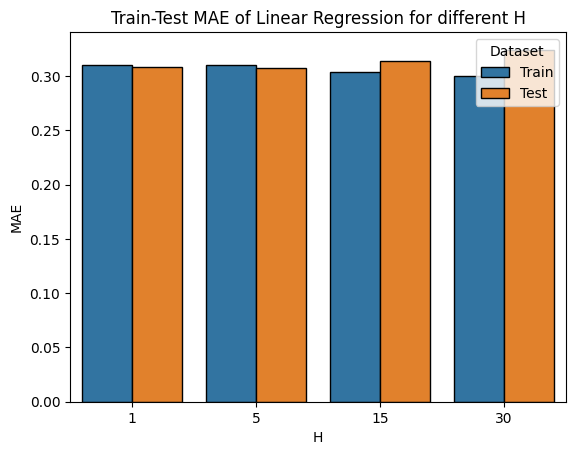

In [11]:
rows = []
for H in [1, 5, 15, 30]:
    x_train, y_train = construct_timeframes(train_df, H)
    x_test, y_test = construct_timeframes(test_df, H)

    model = LinearRegression()
    model.fit(x_train, y_train)

    rows.append({'H': H, 'Dataset': 'Train',
                 'MAE': mean_absolute_error(y_train, model.predict(x_train))})
    rows.append({'H': H, 'Dataset': 'Test',
                 'MAE': mean_absolute_error(y_test, model.predict(x_test))})
metrics_df = pd.DataFrame(rows)
ax = sns.barplot(metrics_df, x='H', y='MAE', hue='Dataset', edgecolor='black')
ax.set_title('Train-Test MAE of Linear Regression for different H')
ax

## Task 6

In [12]:
H = 30
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

train_dates = train_df['Date'].iloc[H:]
test_dates = test_df['Date'].iloc[H:]

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=train_dates.iloc[-H:], y=y_train[-H:],
    mode='lines', name='Train (Actual)',
    line=dict(color='royalblue', width=2)
))
fig.add_trace(go.Scatter(
    x=train_dates.iloc[-H:], y=y_pred_train[-H:],
    mode='lines', name='Train (Predicted)',
    line=dict(color='orange', width=2.5)
))

fig.add_trace(go.Scatter(
    x=test_dates, y=y_test,
    mode='lines', name='Test (Actual)',
    line=dict(color='royalblue', width=2, dash='dash')
))
fig.add_trace(go.Scatter(
    x=test_dates, y=y_pred_test,
    mode='lines', name='Test (Predicted)',
    line=dict(color='#E63946', width=2.5)
))

fig.add_shape(
    type='line',
    x0=test_dates.iloc[0], x1=test_dates.iloc[0],
    y0=0, y1=1, xref='x', yref='paper',
    line=dict(color='black', width=2, dash='dash')
)

fig.update_layout(
    title='USD Price Index: Close Price Prediction (H=30)',
    xaxis_title='Date',
    yaxis_title='Price',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99),
    hovermode='x unified',
    width=1300, height=650
)

fig.show()

## Task 7

Dataset        Test               Train        
Model   Log-Returns  Prices Log-Returns  Prices
H                                              
1            0.3083  0.3081      0.3094  0.3104
5            0.3057  0.3078      0.3088  0.3099
15           0.3124  0.3144      0.3041  0.3040
30           0.3206  0.3244      0.2988  0.2998


Text(0.5, 1.03, 'MAE in absolute prices: Prices vs Log-Returns')

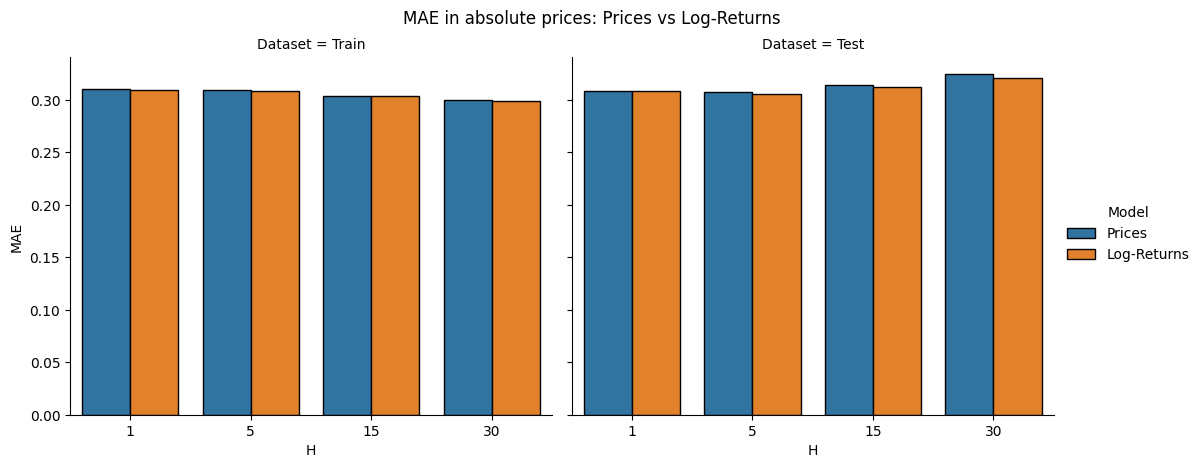

In [13]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars] / df_logr[vars].shift(1))

split = len(train_df)
train_logr = df_logr.iloc[:split].dropna()
test_logr = df_logr.iloc[split:]

close = df['Close'].to_numpy(dtype=np.float64)

def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

rows = []
for H in [1, 5, 15, 30]:
    x_train, y_train = construct_timeframes(train_logr, H)
    x_test, y_test = construct_timeframes(test_logr, H)

    model = LinearRegression()
    model.fit(x_train, y_train)

    for name, frame, x in [('Train', train_logr, x_train), ('Test', test_logr, x_test)]:
        idx = frame.index[H:].to_numpy()
        prev_close = close[idx - 1]
        pred_abs = log_returns_to_absolute_prices(prev_close, model.predict(x))
        true_abs = close[idx]
        rows.append({'H': H, 'Dataset': name, 'Model': 'Log-Returns',
                     'MAE': mean_absolute_error(true_abs, pred_abs)})

metrics_logr_df = pd.DataFrame(rows)

metrics_price_df = metrics_df.copy()
metrics_price_df['Model'] = 'Prices'
compare_df = pd.concat([metrics_price_df, metrics_logr_df], ignore_index=True)
print(compare_df.pivot_table(index='H', columns=['Dataset', 'Model'], values='MAE').round(4))

g = sns.catplot(compare_df, x='H', y='MAE', hue='Model', col='Dataset',
                kind='bar', edgecolor='black', height=4.5, aspect=1.2)
g.figure.suptitle('MAE in absolute prices: Prices vs Log-Returns', y=1.03)

After converting the forecasts into absolute values, both models exhibit nearly identical MAE (for all H values). The model based on log-returns performs marginally better on the test set, though the difference is tiny. Increasing the H is not causing better performance since MAE increases slightly, which indicates a sign of overfitting. While with log-returns the series become stationary, this does not result in reduction of error.

## Task 8

In [14]:
history_size = 30

data = train_df[['Close', 'Open']]
data = np.log(data / data.shift(1)).dropna()

results = grangercausalitytests(data[['Close', 'Open']], maxlag=history_size)

p_values = {lag: results[lag][0]['ssr_ftest'][1] for lag in range(1, history_size + 1)}
results_df = pd.DataFrame({'Lag (H)': list(p_values.keys()),
                           'P-value': list(p_values.values())})
results_df['Significant'] = results_df['P-value'] < 0.05
results_df

,Lag (H),P-value,Significant
0,1,0.191609,False
1,2,0.820257,False
2,3,0.525268,False
3,4,0.785338,False
4,5,0.025691,True
5,6,0.636667,False
6,7,0.725205,False
7,8,0.392926,False
8,9,0.278278,False
9,10,0.493648,False


The Granger Causality Test was applied, and `Open` price does not improve the prediction of the `Close` price. For most time steps, the p-value is greater than 0.05, therefore the null hypothesis is not rejected. For an isolated instance with `p<0.05` (H = 5), a falsely significant result is to be expected by chance.

## Task 9

In [15]:
df_feat = df.copy()
df_feat['Date'] = df_feat['Date'].dt.tz_localize(None).dt.normalize()

sp = yf.Ticker('^GSPC').history(period='10y')[['Close']].rename(columns={'Close': 'SP500'}).reset_index()
sp['Date'] = sp['Date'].dt.tz_localize(None).dt.normalize()

df_feat = df_feat.merge(sp, on='Date', how='left')
df_feat['SP500'] = df_feat['SP500'].ffill()
df_feat = df_feat.dropna().reset_index(drop=True)

us_holidays = holidays.country_holidays('US')
df_feat['Holiday'] = df_feat['Date'].dt.date.map(lambda d: int(d in us_holidays))
df_feat['DayOfWeek'] = df_feat['Date'].dt.dayofweek
df_feat['Month'] = df_feat['Date'].dt.month
print(df_feat['Holiday'].value_counts())


df_feat = pd.get_dummies(df_feat, columns=['DayOfWeek', 'Month'], dtype=float)

past_cols = ['Open', 'High', 'Low', 'Close', 'SP500']
future_cols = ['Holiday'] + [c for c in df_feat.columns if c.startswith(('DayOfWeek_', 'Month_'))]

def construct_timeframes(df, H, past_cols, future_cols):
    past = df[past_cols].to_numpy(dtype=np.float64)
    fut = df[future_cols].to_numpy(dtype=np.float64)
    x = np.array([np.concatenate([past[i-H:i].flatten(), fut[i]]) for i in range(H, len(df))])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

split = int(len(df_feat) * 0.7)
train_f, test_f = df_feat.iloc[:split], df_feat.iloc[split:]

H = 30
x_train, y_train = construct_timeframes(train_f, H, past_cols, future_cols)
x_test, y_test = construct_timeframes(test_f, H, past_cols, future_cols)

model = LinearRegression().fit(x_train, y_train)
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

print('Train MAE:', mean_absolute_error(y_train, y_pred_train))
print('Test MAE: ', mean_absolute_error(y_test, y_pred_test))

train_dates = train_f['Date'].iloc[H:]
test_dates = test_f['Date'].iloc[H:]

fig = go.Figure()
fig.add_trace(go.Scatter(x=train_dates.iloc[-H:], y=y_train[-H:], mode='lines',
                         name='Train (Actual)', line=dict(color='royalblue', width=2)))
fig.add_trace(go.Scatter(x=train_dates.iloc[-H:], y=y_pred_train[-H:], mode='lines',
                         name='Train (Predicted)', line=dict(color='orange', width=2.5)))
fig.add_trace(go.Scatter(x=test_dates, y=y_test, mode='lines',
                         name='Test (Actual)', line=dict(color='royalblue', width=2, dash='dash')))
fig.add_trace(go.Scatter(x=test_dates, y=y_pred_test, mode='lines',
                         name='Test (Predicted)', line=dict(color='#E63946', width=2.5)))
fig.add_shape(type='line', x0=test_dates.iloc[0], x1=test_dates.iloc[0], y0=0, y1=1,
              xref='x', yref='paper', line=dict(color='black', width=2, dash='dash'))
fig.update_layout(title='USD Price Index: Close Price Prediction with extra features (H=30)',
                  xaxis_title='Date', yaxis_title='Price', template='plotly_white',
                  legend=dict(x=0.01, y=0.99), hovermode='x unified', width=1300, height=650)
fig.show()

Holiday
0    2492
1      22
Name: count, dtype: int64
Train MAE: 0.29044480567447983
Test MAE:  0.3383514207709885


The predictions track the actual values very closely, but appear slightly lagged and are less accurate during sharp changes. The MAE is 0.290 on the training set and 0.338 on the test set, indicating that the additional features did not improve the predictions.